# 📥 Carga de datos

### 🎯 Goal
Understand what each table contains (size, columns, types, typical values) before cleaning anything.

### 📥 Input
Three CSV files downloaded with `kagglehub` from the Kaggle dataset `br33sa/gender-representation-in-video-games`:

| Table | One row is... | Links to |
|---|---|---|
| `games` | a game | `characters.Game` |
| `characters` | a relevant character | `games.Game_Id`, `sexualization.Id` |
| `sexualization` | the sexualization rating of a character | `characters.Id` |

### 🛠️ What we do
1. Import the libraries (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, `kagglehub`, `os`) and set the plot defaults: `sns.set_style("whitegrid")` and figure size `(10, 6)`.
2. Download the dataset with `kagglehub.dataset_download("br33sa/gender-representation-in-video-games")` and store the folder in `path`.
3. Read each CSV with `pd.read_csv(os.path.join(path, ...))` into `games`, `characters` and `sexualization`.
4. For each table, check `shape`, `columns.tolist()`, `head()` and `info()`.
5. Summarize with `describe()` (numeric columns) and `describe(exclude='number')` (text columns).

### 📝 Observations
*(Fill in after running the code.)*
- e.g. `Unnamed: 27` is completely empty: a column to drop.
- e.g. `Percentage_non_male` and `Team_percentage` are stored as text.
- Full column definitions: `docs/data-dictionary.md`.

In [67]:
# 1. Imports and plot defaults

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display, Markdown

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


In [68]:
# 2. Download the dataset

path = kagglehub.dataset_download("br33sa/gender-representation-in-video-games")
print("path to files:", path)

path to files: /root/.cache/kagglehub/datasets/br33sa/gender-representation-in-video-games/versions/3


In [69]:
# 3. Read each CSV

games = pd.read_csv(os.path.join(path, "games.grivg.csv"))
characters = pd.read_csv(os.path.join(path, "characters.grivg.csv"))
sexualization = pd.read_csv(os.path.join(path, "sexualization.grivg.csv"))

tables = {"games": games, "characters": characters, "sexualization": sexualization}

descriptions = {
    "games": "Information about the games. Each row represents a game. Includes genre, development team, and critic reviews.",
    "characters": "Information about the characters. Each row represents a relevant character. Joins with `games` by `Game`.",
    "sexualization": "Information about the sexualization ratings of characters. Each row represents a rating for a character. Joins by `Id`.",
}

In [70]:
# 4. Check structure of each table

for name, d in tables.items():
    display(Markdown(f"#### {name}\n\n{descriptions[name]}"))
    print(f"shape: {d.shape}\n")
    print(f"columns: {d.columns.tolist()}\n")
    display(d.head())
    d.info()
    print("\n")

#### games

Information about the games. Each row represents a game. Includes genre, development team, and critic reviews.

shape: (64, 28)

columns: ['Game_Id', 'Title', 'Release', 'Series', 'Genre', 'Sub-genre', 'Developer', 'Publisher', 'Country', 'Platform', 'PEGI', 'Customizable_main', 'Protagonist', 'Protagonist_Non_Male', 'Relevant_males', 'Relevant_no_males', 'Percentage_non_male', 'Criteria', 'Director', 'Total_team', 'female_team', 'Team_percentage', 'Metacritic ', 'Destructoid', 'IGN', 'GameSpot', 'Avg_Reviews', 'Unnamed: 27']



,Game_Id,Title,Release,Series,Genre,Sub-genre,Developer,Publisher,Country,Platform,...,Director,Total_team,female_team,Team_percentage,Metacritic,Destructoid,IGN,GameSpot,Avg_Reviews,Unnamed: 27
0,GTAV,Grand Theft Auto V,Nov-13,GTA,Action-adventure,Action-adventure,Rockstar North,Rockstar Games,GBR,Multi,...,M,7,0,0%,9.7,9.0,10.0,9.0,9.4,NaN
1,PSS,Pokémon Sword/Shield,Nov-19,Pokémon,RPG,RPG,Game Freak,Nintendo,JPN,Nintendo Switch,...,M,9,1,11%,8.0,7.0,9.3,9.0,8.3,NaN
2,CODMW,Call of Duty: Modern Warfare,Oct-19,Call of Duty,Action,FPS,Infinity Ward,Activision,USA,Multi,...,M,11,0,0%,8.0,8.0,8.0,7.0,7.8,NaN
3,RDR2,Red Dead Redemption 2,Dec-18,Red Dead,Action-adventure,Action-adventure,Rockstar Studios,Rockstar Games,USA,Multi,...,M,7,0,0%,9.7,9.5,10.0,9.0,9.6,NaN
4,SMO,Super Mario Odyssey,Oct-17,Super Mario,Action-adventure,Action-adventure,Nintendo EDP,Nintendo,JPN,Nintendo Switch,...,M,11,1,9%,9.7,9.5,10.0,10.0,9.8,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Game_Id               64 non-null     object 
 1   Title                 64 non-null     object 
 2   Release               64 non-null     object 
 3   Series                27 non-null     object 
 4   Genre                 64 non-null     object 
 5   Sub-genre             64 non-null     object 
 6   Developer             64 non-null     object 
 7   Publisher             64 non-null     object 
 8   Country               64 non-null     object 
 9   Platform              64 non-null     object 
 10  PEGI                  64 non-null     int64  
 11  Customizable_main     64 non-null     object 
 12  Protagonist           64 non-null     int64  
 13  Protagonist_Non_Male  64 non-null     int64  
 14  Relevant_males        64 non-null     int64  
 15  Relevant_no_males     64 

#### characters

Information about the characters. Each row represents a relevant character. Joins with `games` by `Game`.

shape: (637, 12)

columns: ['Name', 'Gender', 'Game', 'Age', 'Age_range', 'Playable', 'Sexualization', 'Id', 'Species', 'Side', 'Relevance', 'Romantic_Interest']



... (2 outputs left out)

#### sexualization

Information about the sexualization ratings of characters. Each row represents a rating for a character. Joins by `Id`.

shape: (637, 6)

columns: ['Id', 'Sexualized_clothing', 'Trophy', 'Damsel in Distress', 'Sexualized Cutscenes', 'Total']



,Id,Sexualized_clothing,Trophy,Damsel in Distress,Sexualized Cutscenes,Total
0,CODMW_Farah,0,0,0,0,0
1,PSS_Protagonist,0,0,0,0,0
2,PSS_Magnolia,0,0,0,0,0
3,PSS_Sonia,0,0,0,0,0
4,PSS_Marnie,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 637 entries, 0 to 636
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Id                    637 non-null    object
 1   Sexualized_clothing   637 non-null    int64 
 2   Trophy                637 non-null    int64 
 3   Damsel in Distress    637 non-null    int64 
 4   Sexualized Cutscenes  637 non-null    int64 
 5   Total                 637 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 30.0+ KB




In [71]:
# 5. Descriptive statistics

for name, d in tables.items():
    display(Markdown(f"#### {name}"))
    display(d.describe())                       # numeric columns
    display(d.describe(exclude="number"))       # text columns

#### games

,PEGI,Protagonist,Protagonist_Non_Male,Relevant_males,Relevant_no_males,Total_team,female_team,Metacritic,Destructoid,IGN,GameSpot,Avg_Reviews,Unnamed: 27
count,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,57.000000,62.000000,62.000000,64.000000,0.0
mean,13.484375,1.250000,0.546875,6.140625,3.812500,6.765625,0.718750,8.906250,9.150877,9.261290,8.840323,9.043750,NaN
std,4.611897,0.590937,0.561452,3.939491,2.635984,3.544467,1.030776,0.440373,0.692594,0.556439,0.763181,0.433837,NaN
min,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,7.900000,7.000000,8.000000,7.000000,7.800000,NaN
25%,7.000000,1.000000,0.000000,3.000000,2.000000,3.750000,0.000000,8.700000,9.000000,9.000000,8.125000,8.700000,NaN
50%,16.000000,1.000000,1.000000,6.000000,4.000000,7.000000,0.000000,8.900000,9.000000,9.300000,9.000000,9.000000,NaN
75%,18.000000,1.000000,1.000000,8.250000,5.000000,9.000000,1.000000,9.200000,9.500000,9.600000,9.000000,9.325000,NaN
max,18.000000,4.000000,2.000000,17.000000,14.000000,16.000000,4.000000,9.700000,10.000000,10.000000,10.000000,9.900000,NaN


,Game_Id,Title,Release,Series,Genre,Sub-genre,Developer,Publisher,Country,Platform,Customizable_main,Percentage_non_male,Criteria,Director,Team_percentage
count,64,64,64,27,64,64,64,64,64,64,64,64,64,64,64
unique,64,64,50,25,6,21,54,44,13,8,3,35,3,2,18
top,GTAV,Grand Theft Auto V,Mar-15,Pokémon,Action-adventure,Action-adventure,FromSoftware,Nintendo,USA,Multi,No,33%,TR,M,0%
freq,1,1,3,2,21,16,4,6,24,47,49,5,53,62,36


#### characters

,Playable,Sexualization
count,637.000000,637.000000
mean,0.193093,0.086342
std,0.395035,0.389022
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,3.000000


,Name,Gender,Game,Age,Age_range,Id,Species,Side,Relevance,Romantic_Interest
count,637,637,637,637,637,637,637,637,637,637
unique,616,4,64,59,8,637,10,3,6,3
top,Protagonist,Male,IWATE,Adult,Adult,CODMW_Farah,Human,P,SC,No
freq,4,393,27,231,264,1,482,426,266,589


#### sexualization

,Sexualized_clothing,Trophy,Damsel in Distress,Sexualized Cutscenes,Total
count,637.000000,637.000000,637.000000,637.000000,637.000000
mean,0.029827,0.010989,0.028257,0.017268,0.086342
std,0.170244,0.104333,0.165838,0.130372,0.389022
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,3.000000


,Id
count,637
unique,637
top,CODMW_Farah
freq,1


# 🔍 Exploración

> We look for problems in the data (missing values, duplicates, outliers, inconsistencies) and study the variables alone and in pairs.

---

### 🎯 Goal
Find what needs cleaning and what the data already tells us, before changing anything.

### 📥 Input
The three tables loaded in *Carga* (`games`, `characters`, `sexualization`), still unmodified.

### 🛠️ What we do
1. **Missing values:** count nulls per column (`df.isnull().sum()`) and show the percentage (`nulls / len(df) * 100`), only for columns above 0. Optional: `missingno` matrix.
2. **Duplicates:** `df.duplicated().sum()`.
3. **Univariate analysis** (at least 3 variables):
   - categorical (e.g. `Gender`, `Genre`) → bar chart of `value_counts()`
   - numeric (e.g. `Avg_Reviews`, `Total_team`) → histogram
   - extreme values → boxplot
4. **Bivariate analysis** (at least 3 relationships):
   - category vs category → `pd.crosstab(..., normalize="index") * 100` + grouped bars (e.g. `Gender` × `Sexualization`)
   - number vs category → boxplot by group (e.g. `Team_percentage` by `Director`)
5. **Outliers:** IQR rule, flagged outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`, plus boxplots.
6. **Dubious data:** check consistency between columns (e.g. `characters.Sexualization` vs `sexualization.Total`) and impossible values (e.g. ages).

### 📊 Charts checklist
Every chart has a title, named axes, and a legend when it has more than one series. Minimum **5 visualizations** in total.

### 📝 Observations and decisions
*(Fill in after running the code. Nothing is changed in this section: decisions are applied in *Limpieza*.)*

| Finding | Where | What we will do | Why |
|---|---|---|---|
| *(e.g. `Series` has 58% nulls)* | `games` | *(keep / fill / drop)* | *(reason)* |
| *(e.g. outlier in `Total_team`)* | `games` | *(keep / cap / drop)* | *(reason)* |

#### games

,missing,percent
Unnamed: 27,64,100.0
Series,37,57.8
Destructoid,7,10.9
IGN,2,3.1
GameSpot,2,3.1


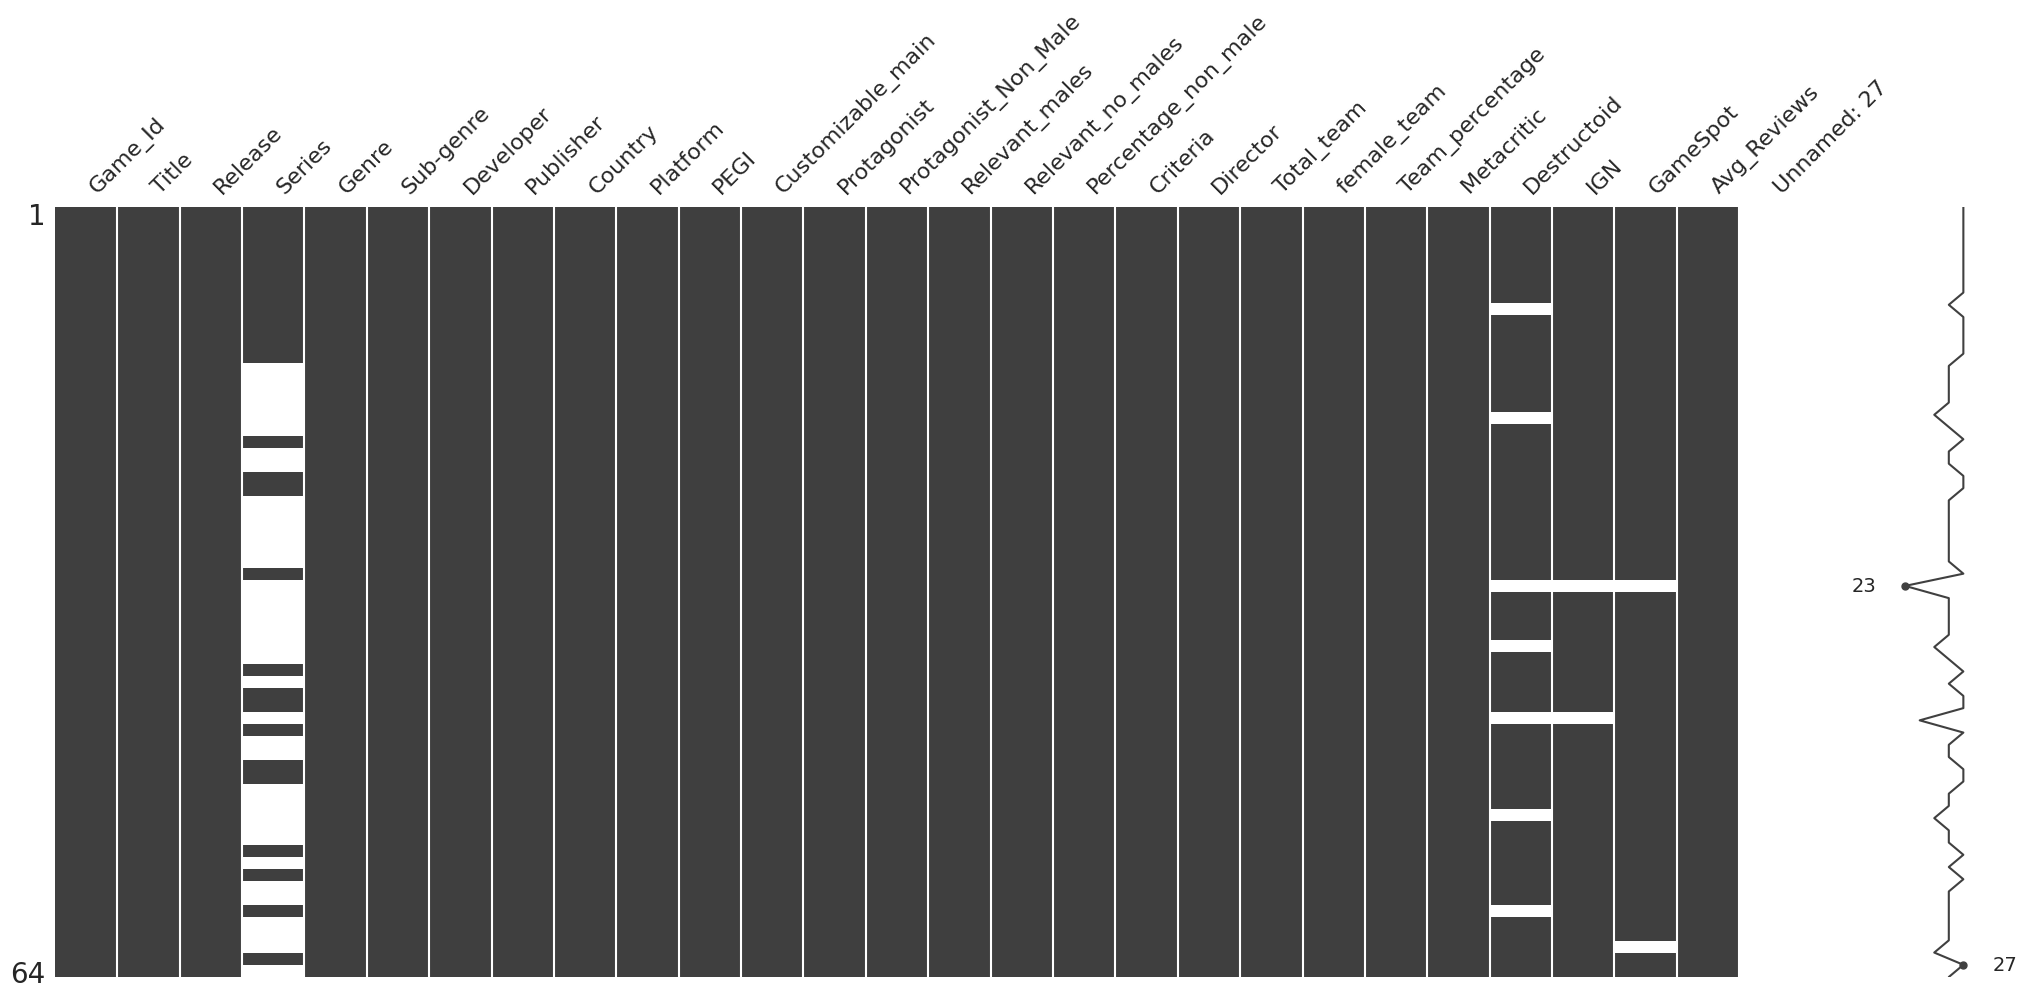

#### characters

No missing values.



#### sexualization

No missing values.



In [64]:
# 1. Missing values

import missingno as msno

for name, d in tables.items():
    display(Markdown(f"#### {name}"))

    nulls = d.isnull().sum()
    nulls = nulls[nulls > 0]

    if nulls.empty:
        print("No missing values.\n")
        continue

    report = pd.DataFrame({
        "missing": nulls,
        "percent": (nulls / len(d) * 100).round(1),
    }).sort_values("percent", ascending=False)
    display(report)

    msno.matrix(d)
    plt.show()



In [ ]:
# Drop the fully empty column created by a trailing comma in the CSV
games = games.drop(columns=["Unnamed: 27"], errors="ignore")
tables["games"] = games

In [75]:
# Series: a missing value means the game belongs to no series, so we label it
games["Series"] = games["Series"].fillna("Standalone")
tables["games"] = games 

# Destructoid, IGN or GameSpot: a missing value means the game has not been rated by this journal so we label it
games["Destructoid"] = games["Destructoid"].fillna("not rated")
games["IGN"] = games["IGN"].fillna("not rated")
games["GameSpot"] = games["GameSpot"].fillna("not rated")
tables["games"] = games 

# Check: no missing values left in those columns
print("Missing in Series:", games["Series"].isnull().sum())
print(games["Series"].value_counts().head(), "\n")

print("Missing in Destructoid:", games["Destructoid"].isnull().sum())
print(games["Destructoid"].value_counts().head(), "\n")

print("Missing in IGN:", games["IGN"].isnull().sum())
print(games["IGN"].value_counts().head(), "\n")

print("Missing in GameSpot:", games["GameSpot"].isnull().sum())
print(games["GameSpot"].value_counts().head(), "\n")

Missing in Series: 0
Series
Standalone      37
Pokémon          2
Call of Duty     2
GTA              1
Super Mario      1
Name: count, dtype: int64 

Missing in Destructoid: 0
Destructoid
9.0          19
10.0         14
9.5          11
not rated     7
8.0           6
Name: count, dtype: int64 

Missing in IGN: 0
IGN
9.0     15
10.0    14
9.3      7
9.5      7
8.8      4
Name: count, dtype: int64 

Missing in GameSpot: 0
GameSpot
9.0     28
8.0     13
10.0    10
8.5      5
7.0      3
Name: count, dtype: int64 



In [65]:
# 2. Duplicates

for name, d in tables.items():
    display(Markdown(f"#### {name}"))
    duplicates = d.duplicated().sum()

    if duplicates > 0:
        display(d[d.duplicated()])
        d.drop_duplicates()

    else:
        print("No duplicates found.\n")

#### games

No duplicates found.



#### characters

No duplicates found.



#### sexualization

No duplicates found.



In [66]:
# 1. Univariate analysis

